<a href="https://colab.research.google.com/github/WIZARDANJALI/Data-Cleaning-Assignment1/blob/main/Time_series_data_quality_tracker_for_iot_device.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

✅ Data Loaded Successfully!
                   timestamp sensor_id  temperature   humidity
0 2025-10-29 13:59:16.211621  Sensor_1    25.993428  52.923146
1 2025-10-29 14:00:16.211635  Sensor_1    24.723471  57.896773
2 2025-10-29 14:01:16.211638  Sensor_1    26.295377  58.286427
3 2025-10-29 14:02:16.211641  Sensor_1    28.046060  55.988614
4 2025-10-29 14:03:16.211643  Sensor_1    24.531693  59.193571

📊 Data Quality Report
----------------------------
Total Rows: 298
Completeness: 100.00%
Duplicate Rows: 0
Invalid Temperature Values: 0
Invalid Humidity Values: 0
Average Time Gap Between Readings: 20.0 seconds

✅ Cleaned data saved as 'clean_data.csv'


/tmp/ipython-input-1356150455.py:56: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  data['temperature'].fillna(data['temperature'].mean(), inplace=True)
/tmp/ipython-input-1356150455.py:57: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, 

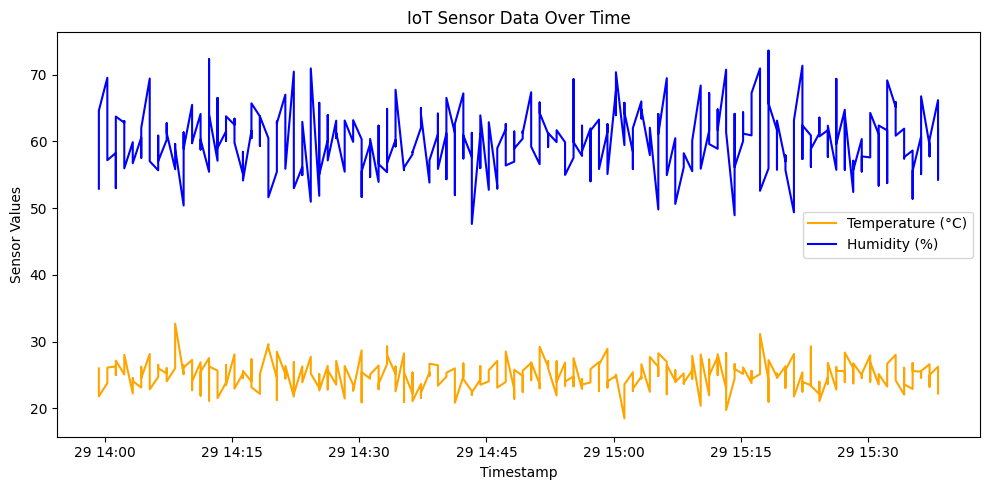

In [5]:


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


data = iot_data.copy()


print("✅ Data Loaded Successfully!")
print(data.head())


missing_values = data.isnull().sum()
completeness = 100 - (missing_values.sum() / (len(data) * len(data.columns))) * 100

duplicates = data.duplicated().sum()

invalid_temp_range = data[(data['temperature'] < -10) | (data['temperature'] > 60)].shape[0]
invalid_humidity_range = data[(data['humidity'] < 0) | (data['humidity'] > 100)].shape[0]

data['timestamp'] = pd.to_datetime(data['timestamp'], errors='coerce')
data = data.sort_values(by='timestamp')
time_diff = data['timestamp'].diff().dt.total_seconds().dropna()
avg_gap = round(time_diff.mean(), 2)

data['temperature'].fillna(data['temperature'].mean(), inplace=True)
data['humidity'].fillna(data['humidity'].mean(), inplace=True)

data = data.drop_duplicates()

print("\n📊 Data Quality Report")
print("----------------------------")
print(f"Total Rows: {len(data)}")
print(f"Completeness: {completeness:.2f}%")
print(f"Duplicate Rows: {duplicates}")
print(f"Invalid Temperature Values: {invalid_temp_range}")
print(f"Invalid Humidity Values: {invalid_humidity_range}")
print(f"Average Time Gap Between Readings: {avg_gap} seconds")

data.to_csv("clean_data.csv", index=False)
print("\n✅ Cleaned data saved as 'clean_data.csv'")

plt.figure(figsize=(10,5))
plt.plot(data['timestamp'], data['temperature'], label='Temperature (°C)', color='orange')
plt.plot(data['timestamp'], data['humidity'], label='Humidity (%)', color='blue')
plt.xlabel('Timestamp')
plt.ylabel('Sensor Values')
plt.title('IoT Sensor Data Over Time')
plt.legend()
plt.tight_layout()
plt.show()